In [1]:
# --- 0. Setup: find the repo root wherever this notebook runs from ------------------------
import os, sys, json, unittest
from pathlib import Path
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "code" / "run_experiment.py").exists())
sys.path.insert(0, str(ROOT / "code"))
os.chdir(ROOT)                                  # so relative paths in configs resolve
print("Repo root:", ROOT)

import run_experiment, evaluate_final, summarise
from obpevo import config as C, core, instances, baselines

Repo root: c:\Users\nicho\Downloads\dsa4212-obp


In [2]:
# --- 1. Evaluator unit tests (scoring is correct before we trust anything else) -----------
res = unittest.TextTestRunner(verbosity=0).run(unittest.defaultTestLoader.discover("tests"))
assert res.wasSuccessful(), "evaluator tests failed"

c:\Users\nicho\Downloads\dsa4212-obp\tests\test_core.py:39: RuntimeWarning: invalid value encountered in sqrt
  core.pack_funsearch(lambda item, bins: np.sqrt(item - bins), items, 100)   # NaN
----------------------------------------------------------------------
Ran 6 tests in 0.082s

OK


In [3]:
# --- 2. Instances: build and eyeball ------------------------------------------------------
CONFIG = "configs/smoke.yaml"                   # fake LLM, no key needed
cfg = C.load(CONFIG)
train = instances.load_set(run_experiment.ensure_instances(cfg) / "train.npz")
print(pd.DataFrame([dict(id=i["id"], n=len(i["items"]), cap=i["capacity"],
                         lb=core.lower_bound(i["items"], i["capacity"])) for i in train]))

# Best Fit on train: the reference every evolved heuristic should beat
bf = -core.score(core.evaluate(baselines.best_fit, train, cfg["evaluation"]["mode"]))
print(f"Best Fit train excess: {bf:.3%}")

          id    n  cap   lb
0  train_000  262  100  105
1  train_001  260  100  103
2  train_002  461  100  185
3  train_003  404  100  159
4  train_004  275  100  109
5  train_005  428  100  171
Best Fit train excess: 4.891%


In [4]:
# --- 3. One small search run (EoH, seed 0) ------------------------------------------------
idx = run_experiment.main(CONFIG, methods=["eoh"], seeds=[0], force=True)
run = C.results_dir(cfg) / "eoh" / "seed0"
s = json.loads((run / "summary.json").read_text())
evals = pd.read_csv(run / "evals.csv")
calls = pd.read_csv(run / "llm_calls.csv")

LLM: fake / fake-heuristic-generator
[smoke] 1 runs | budget {'max_evals': 24, 'max_tokens': 200000, 'max_minutes': 10} | train=train (6 instances)
           eoh seed0: 24 evals (23 ok, 1 err, 0 timeout) | 25 calls, 12,371 tokens | best train excess 0.0489 | budget:evals | 1.56 min
Wrote C:\Users\nicho\Downloads\dsa4212-obp\results\smoke\runs_index.csv (10 runs)


In [5]:
# --- 4. Checks: budgets, logging, reproducibility -----------------------------------------

checks = {
    "stopped on eval budget":      s["stop_reason"] == "budget:evals",
    "evals == max_evals":          len(evals) == cfg["budget"]["max_evals"],
    "no runaway LLM calls":        len(calls) <= 2 * len(evals),          # ReEvo can be ~1.8x
    "most candidates ran":         (evals.status == "ok").mean() >= 0.5,
    "best program saved":          (run / "best_program.py").exists(),
    "per-instance results saved":  len(pd.read_csv(run / "per_instance.csv")) > 0,
}
# Re-score the saved best program from scratch: must match the logged training score
ns = {}; exec((run / "best_program.py").read_text(), ns)
rescored = -core.score(core.evaluate(ns["priority"], train, cfg["evaluation"]["mode"]))
checks["best score reproducible"] = abs(rescored - s["best_train_excess"]) < 1e-12

print(pd.Series(checks).map({True: "PASS", False: "FAIL"}).to_string())
print(evals.status.value_counts().to_dict(), "|", s["n_llm_calls"], "LLM calls,",
      s["prompt_tokens"] + s["completion_tokens"], "tokens")

stopped on eval budget        PASS
evals == max_evals            PASS
no runaway LLM calls          PASS
most candidates ran           PASS
best program saved            PASS
per-instance results saved    PASS
best score reproducible       PASS
{'ok': 23, 'error': 1} | 25 LLM calls, 12371 tokens


In [6]:
# --- 5. Held-out evaluation (optional, ~1 min) --------------------------------------------
summ = evaluate_final.main(CONFIG, sets=["val"])
print(summ[["label", "mean_excess", "delta_vs_bf_pp", "failed_frac"]])

[smoke] 10 program x set jobs on ['val']
               eoh seed0 val                ok
               eoh seed1 val                ok
         funsearch seed0 val                ok
         funsearch seed1 val                ok
         hillclimb seed0 val                ok
         hillclimb seed1 val                ok
        randsample seed0 val                ok
        randsample seed1 val                ok
             reevo seed0 val                ok
             reevo seed1 val                ok
           label set  runs  mean_excess  sd_excess  delta_vs_bf_pp  win_vs_bf  failed_frac
        best_fit val     1      0.04792        NaN         0.00000       0.00          0.0
             eoh val     2      0.04792        0.0         0.00000       0.00          0.0
       funsearch val     2      0.04792        0.0         0.00000       0.00          0.0
       hillclimb val     2      0.04792        0.0         0.00000       0.00          0.0
      randsample val     2      0.

LLM: gemini / gemini-3.5-flash-lite
{'prompt_tokens': 31, 'completion_tokens': 66}
{Prioritize bins with the least remaining capacity that can still fit the item to maximize space utilization and pack tightly.}
```python
def priority(item, bins):
    return min((b, rem) for b, rem in enumerate(bins) if rem >= item), lambda x: x[1]
```
LLM: gemini / gemini-3.5-flash-lite
[pipecheck] 1 runs | budget {'max_evals': 12, 'max_tokens': 60000, 'max_minutes': 8} | train=train (6 instances)
           eoh seed0: 12 evals (12 ok, 0 err, 0 timeout) | 15 calls, 8,743 tokens | best train excess 0.0489 | budget:evals | 0.77 min
Wrote C:\Users\nicho\Downloads\dsa4212-obp\results\pipecheck\runs_index.csv (1 runs)
stopped on eval budget        PASS
no failed API calls           PASS
tokens reported by the API    PASS
cost tracked                  PASS
most candidates ran           PASS
LLM wrote new heuristics      PASS

15 calls | 6,251 in + 2,492 out tokens | notional cost $0.0081 | median latency 3.1

,call,status


,eval,status,error


# eval 3, train excess 0.04891

import numpy as np

def priority(item: float, bins: np.ndarray) -> np.ndarray:
    """Returns priority with which we want to add item to each bin.
    Args:
        item: Size of item to be added to the bin.
        bins: Array of capacities for each bin.
    Return:
        Array of same size as bins with priority score of each bin.
    """
    remaining = bins - item
    return np.where(remaining >= 0, -remaining, -np.inf)


[pipecheck] 2 program x set jobs on ['val', 'test_id']
               eoh seed0 val                ok
               eoh seed0 test_id            ok
           label     set  runs  mean_excess  sd_excess  delta_vs_bf_pp  win_vs_bf  failed_frac
        best_fit test_id     1      0.04402        NaN         0.00000       0.00          0.0
             eoh test_id     1      0.04402        NaN         0.00000       0.00          0.0
       first_fit test_id     1      0.04900        NaN         0.49834       0.00          0.0
almost_w

c:\Users\nicho\Downloads\dsa4212-obp\code\summarise.py:118: RuntimeWarning: All-NaN slice encountered
  med, lo, hi = np.nanmedian(c, 0), np.nanmin(c, 0), np.nanmax(c, 0)


# pipecheck: summary tables

Budget per run: {'max_evals': 12, 'max_tokens': 60000, 'max_minutes': 8}

## Search runs

| label | runs | evals/run | ok % | error % | timeout % | LLM calls/run | tokens/run | cost USD (total) | minutes/run | best train excess % (mean ± sd) |
|---|---|---|---|---|---|---|---|---|---|---|
| eoh | 1 | 12.0 | 100.0 | 0.0 | 0.0 | 15.0 | 8743 | 0.008 | 0.77 | 4.891 ± 0.000 |

## Held-out sets: excess over lower bound (%), mean ± sd across seeds

| label | val | test_id |
|---|---|---|
| eoh | 4.79 | 4.40 |
| first_fit | 5.17 | 4.90 |
| best_fit | 4.79 | 4.40 |
| worst_fit | 13.49 | 13.04 |
| almost_worst_fit | 8.07 | 8.80 |
| next_fit | 28.37 | 29.40 |

Figures in C:\Users\nicho\Downloads\dsa4212-obp\results\pipecheck\figures


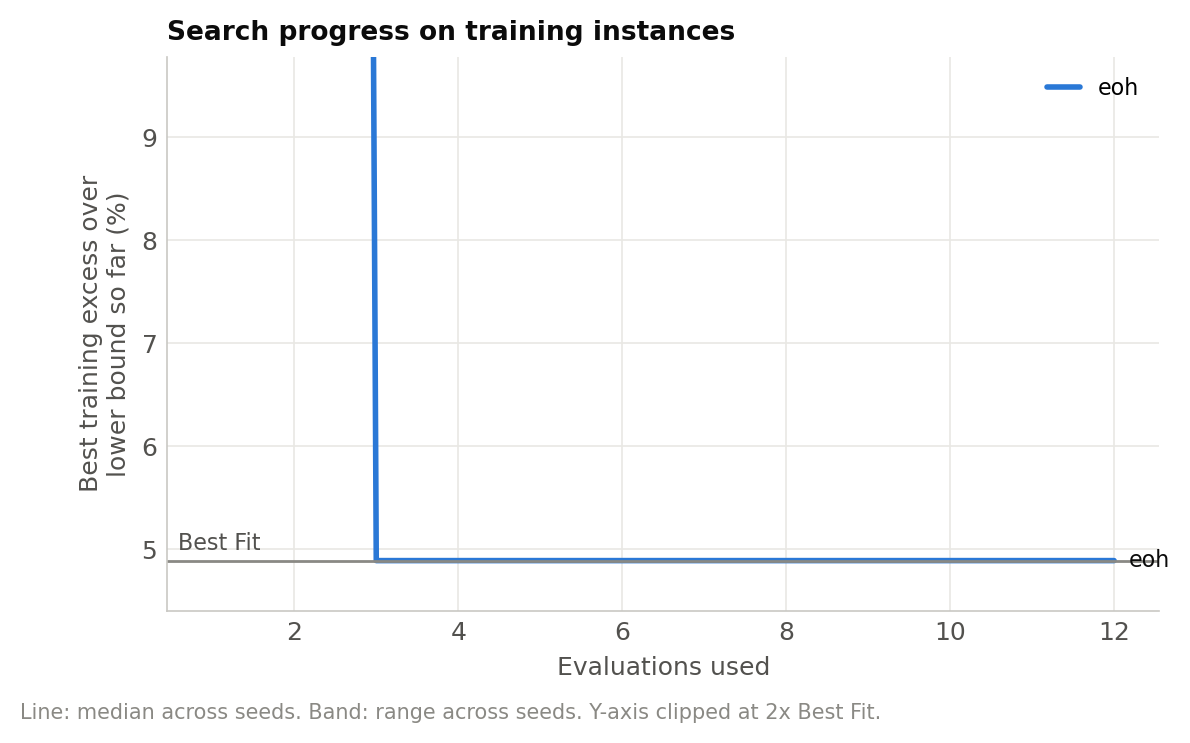

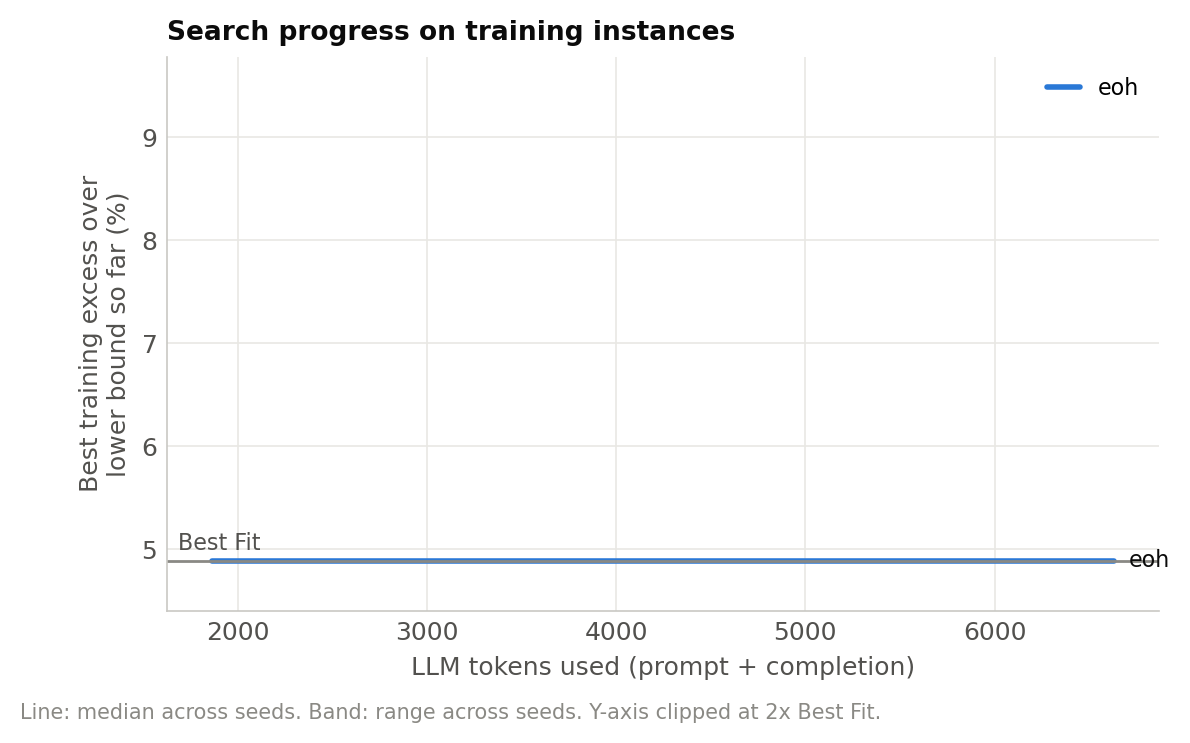

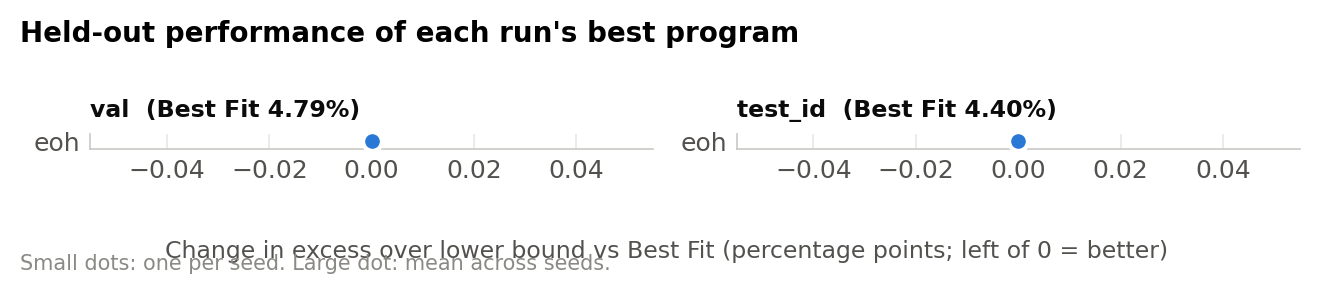

In [ ]:
# --- 6. Real LLM check with Gemini (free tier) ---------------------------------------------
# Check pipeline using pipeline.yaml first (12 evals, population 4)
# 6a. API key: from .env in the repo root (GEMINI_API_KEY=...), or paste it below. Never commit it.
try:
    from dotenv import load_dotenv                      # %pip install python-dotenv
    load_dotenv(ROOT / ".env")
except ImportError:
    pass
# os.environ["GEMINI_API_KEY"] = "AIza..."             # alternative: paste here, clear before sharing
assert os.environ.get("GEMINI_API_KEY"), "GEMINI_API_KEY is not set"

from obpevo.llm import make_backend

CONFIG = "configs/pipecheck.yaml"                       # Gemini, 12 evals, 6 small instances
OV = {"evaluation": {"timeout_seconds": 90}}            # Windows: room for per-candidate process start-up
cfg = C.load(CONFIG, OV)
print("LLM:", cfg["llm"]["provider"], "/", cfg["llm"]["model"])

# 6b. One direct call first: checks key, model name and reply format in seconds, before the pipeline
client = make_backend(cfg["llm"])
text, usage = client.complete("Write a Python function priority(item, bins) for online bin packing. "
                              "Reply with one line of reasoning in {braces}, then the code.")
print(usage)
print(text[:600])

# 6c. Small EoH run with the real LLM
idx = run_experiment.main(CONFIG, methods=["eoh"], seeds=[0], force=True, overrides=OV)
run = C.results_dir(cfg) / "eoh" / "seed0"
s = json.loads((run / "summary.json").read_text())
evals = pd.read_csv(run / "evals.csv")
calls = pd.read_csv(run / "llm_calls.csv")
cands = pd.read_json(run / "candidates.jsonl", lines=True)

# 6d. Checks specific to a real LLM
template = "return item - bins"                         # the Best Fit body in the prompt template
checks = {
    "stopped on eval budget":        s["stop_reason"] == "budget:evals",
    "no failed API calls":           (calls.status == "ok").all(),
    "tokens reported by the API":    (calls.token_source == "api").all(),
    "cost tracked":                  calls.cost_usd.sum() > 0,
    "most candidates ran":           (evals.status == "ok").mean() >= 0.5,
    "LLM wrote new heuristics":      (~cands.program.str.contains(template, regex=False)).sum() >= 3,
}
print(pd.Series(checks).map({True: "PASS", False: "FAIL"}).to_string())

print(f"\n{len(calls)} calls | {calls.prompt_tokens.sum():,} in + {calls.completion_tokens.sum():,} out tokens"
      f" | notional cost ${calls.cost_usd.sum():.4f} | median latency {calls.latency_s.median():.1f}s")
print(evals.status.value_counts().to_dict())
print(f"best train excess {s['best_train_excess']:.3%} vs Best Fit {bf:.3%}")

# Failures, if any: why the API call or the candidate failed
display(calls[calls.status != "ok"][["call", "status"]].head())
display(evals[evals.status != "ok"][["eval", "status", "error"]].head())

# 6e. The best heuristic the LLM found
print((run / "best_program.py").read_text())

# 6f. Held-out evaluation, tables and figures (cost and token plots included)
summ = evaluate_final.main(CONFIG, overrides=OV)
figs = summarise.main(CONFIG, overrides=OV)
from IPython.display import Image
for name in ["convergence_evals", "convergence_tokens", "test_sets"]:
    display(Image(figs / f"{name}.png", width=650))